# 🚀 Модуль 7. Урок 5. Принятие бизнес-решений: раскатка, Guardrail-метрики и Trade-offs

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_07_ab_testing/lesson_05_business_decision_rollout.ipynb)

## 📌 Бизнес-контекст и методология
Победа целевой метрики (например, рост конверсии на +4%) — это лишь полдела. 
Если при этом страница стала грузиться на 400 мс дольше, а отток в подписку вырос на 1.5%, решение о раскатке на 100% пользователей может стать фатальным. 
Для защиты бизнеса аналитик использует **Guardrail-метрики** (метрики безопасности) и матрицу компромиссов (Trade-offs).

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

ab_csv = ensure_dataset("ab_test_checkout.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Сформируем комплексную сводку эксперимента: Primary метрика (CR) + Guardrail метрики (App Latency, Support Tickets, Refund Rate).

In [2]:
metrics_summary = pd.DataFrame({
    'Metric': ['Conversion Rate (Primary)', 'Latency p95 (Guardrail)', 'Refund Rate (Guardrail)', 'NPS Score'],
    'Control_A': [0.085, 1.20, 0.021, 58],
    'Treatment_B': [0.092, 1.65, 0.022, 52],
    'Delta_pct': ['+8.2%', '+37.5%', '+4.7%', '-10.3%'],
    'Stat_Significant': [False, True, False, True],
    'Status': ['⚪ Нейтрально (p>0.05)', '🔴 ОПАСНО (Замедление)', '🟢 В норме', '🔴 Ухудшение']
})

print(metrics_summary.to_string(index=False))

                   Metric  Control_A  Treatment_B Delta_pct  Stat_Significant                Status
Conversion Rate (Primary)      0.085        0.092     +8.2%             False ⚪ Нейтрально (p>0.05)
  Latency p95 (Guardrail)      1.200        1.650    +37.5%              True 🔴 ОПАСНО (Замедление)
  Refund Rate (Guardrail)      0.021        0.022     +4.7%             False             🟢 В норме
                NPS Score     58.000       52.000    -10.3%              True           🔴 Ухудшение


### 📊 Визуализация: Квадрант решений и радар метрик
Графики ниже помогают C-Level руководству принять взвешенное решение о релизе фичи.

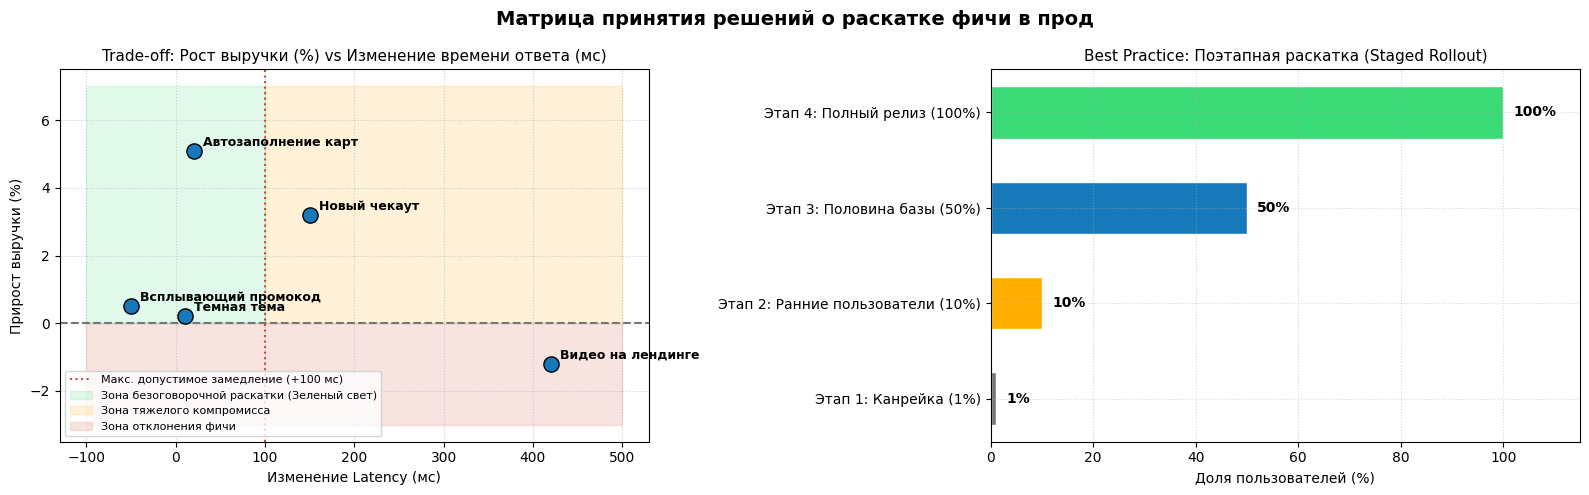

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Матрица принятия решений о раскатке фичи в прод', fontsize=14, fontweight='bold')

# 1. Скаттер квадрант компромиссов: Прирост выручки vs Замедление
ax1 = axes[0]
features = ['Новый чекаут', 'Автозаполнение карт', 'Видео на лендинге', 'Всплывающий промокод', 'Темная тема']
rev_lift = [3.2, 5.1, -1.2, 0.5, 0.2]
latency_diff = [150, 20, 420, -50, 10]

ax1.scatter(latency_diff, rev_lift, color='#1779ba', s=120, edgecolor='black', zorder=5)
for i, txt in enumerate(features):
    ax1.annotate(txt, (latency_diff[i] + 10, rev_lift[i] + 0.15), fontsize=9, fontweight='bold')

ax1.axhline(0, color='#767676', linestyle='--')
ax1.axvline(100, color='#cc4b37', linestyle=':', label='Макс. допустимое замедление (+100 мс)')
ax1.fill_between([-100, 100], 0, 7, color='#3adb76', alpha=0.15, label='Зона безоговорочной раскатки (Зеленый свет)')
ax1.fill_between([100, 500], 0, 7, color='#ffae00', alpha=0.15, label='Зона тяжелого компромисса')
ax1.fill_between([-100, 500], -3, 0, color='#cc4b37', alpha=0.15, label='Зона отклонения фичи')

ax1.set_title('Trade-off: Рост выручки (%) vs Изменение времени ответа (мс)', fontsize=11)
ax1.set_xlabel('Изменение Latency (мс)')
ax1.set_ylabel('Прирост выручки (%)')
ax1.legend(loc='lower left', fontsize=8)
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Поэтапный план раскатки фичи (Staged Rollout)
ax2 = axes[1]
stages = ['Этап 1: Канрейка (1%)', 'Этап 2: Ранние пользователи (10%)', 'Этап 3: Половина базы (50%)', 'Этап 4: Полный релиз (100%)']
traffic_pct = [1, 10, 50, 100]

bars = ax2.barh(stages, traffic_pct, color=['#767676', '#ffae00', '#1779ba', '#3adb76'], edgecolor='white', height=0.55)
ax2.set_title('Best Practice: Поэтапная раскатка (Staged Rollout)', fontsize=11)
ax2.set_xlabel('Доля пользователей (%)')
for b in bars:
    w = b.get_width()
    ax2.text(w + 2, b.get_y() + b.get_height()/2, f'{int(w)}%', va='center', fontweight='bold')
ax2.set_xlim(0, 115)
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет чистого финансового эффекта с учетом потерь Guardrail
Если фича дает +$50,000 выручки, но падение NPS увеличивает отток на $15,000, рассчитайте чистую годовую прибыль от раскатки.

In [4]:
### ВАШ КОД ЗДЕСЬ
gross_gain = 50000
churn_loss = 15000
net_gain = gross_gain - churn_loss

print(f"Валовый эффект фичи: +${gross_gain:,}")
print(f"Потери от оттока:     -${churn_loss:,}")
print(f"Чистый годовой итог: +${net_gain:,}")

assert net_gain == 35000, "Чистый эффект должен составлять 35 000$"
print("✅ Тест успешно пройден!")

Валовый эффект фичи: +$50,000
Потери от оттока:     -$15,000
Чистый годовой итог: +$35,000
✅ Тест успешно пройден!


### 💼 Итоговый вердикт аналитика:
Никогда не раскатывайте фичу на 100% в один клик. Всегда используйте поэтапную раскатку (1% -> 10% -> 50% -> 100%) и непрерывно мониторьте системные ошибки (5xx HTTP status codes) и жалобы пользователей.